# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [81]:
# Import necessary libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.layers import TextVectorization, Embedding
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder

from PIL import Image
from collections import Counter
import json
import re
from sentence_transformers import SentenceTransformer

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [3]:
# Dataset path
DATASET_PATH = "./realwaste-main/RealWaste/"

# Get waste categories
categories = os.listdir(DATASET_PATH)

# Count images in each category
category_counts = {}

for category in categories:
    category_path = os.path.join(DATASET_PATH, category)

    if os.path.isdir(category_path):
        images = os.listdir(category_path)
        category_counts[category] = len([
            img for img in images
            if img.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

# Create DataFrame
category_df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Image Count"]
)

print("Number of Categories:", len(category_df))
print("Total Images:", category_df["Image Count"].sum())

display(category_df)

Number of Categories: 9
Total Images: 4752


,Category,Image Count
0,Paper,500
1,Metal,790
2,Cardboard,461
3,Food Organics,411
4,Glass,420
5,Vegetation,436
6,Textile Trash,318
7,Miscellaneous Trash,495
8,Plastic,921


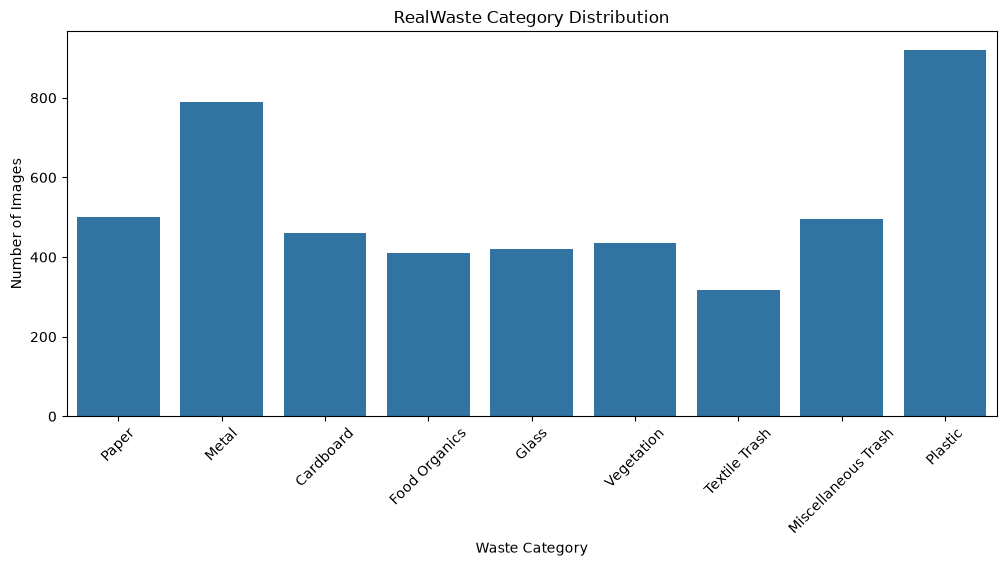

In [4]:
# - Distribution of waste categories

plt.figure(figsize=(12, 5))
sns.barplot(data=category_df, x="Category", y="Image Count")

plt.title("RealWaste Category Distribution")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

,Width,Height
count,4752.0,4752.0
mean,524.0,524.0
std,0.0,0.0
min,524.0,524.0
25%,524.0,524.0
50%,524.0,524.0
75%,524.0,524.0
max,524.0,524.0


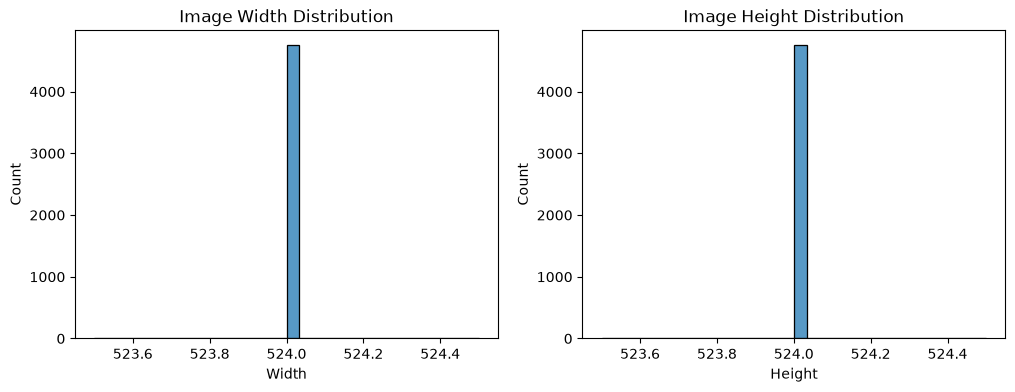

In [5]:
# - Image characteristics (resolution, quality, background)
# image resolution distribution

# Collect image dimensions
image_info = []

for category in categories:
    category_path = os.path.join(DATASET_PATH, category)

    if not os.path.isdir(category_path):
        continue

    for filename in os.listdir(category_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(category_path, filename)

            with Image.open(image_path) as img:
                width, height = img.size
                image_info.append([width, height])

# Create DataFrame
image_df = pd.DataFrame(image_info, columns=["Width", "Height"])

# Display image statistics
display(image_df.describe())

# Visualize image dimensions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(image_df["Width"], bins=30, ax=axes[0])
axes[0].set_title("Image Width Distribution")

sns.histplot(image_df["Height"], bins=30, ax=axes[1])
axes[1].set_title("Image Height Distribution")

plt.show()

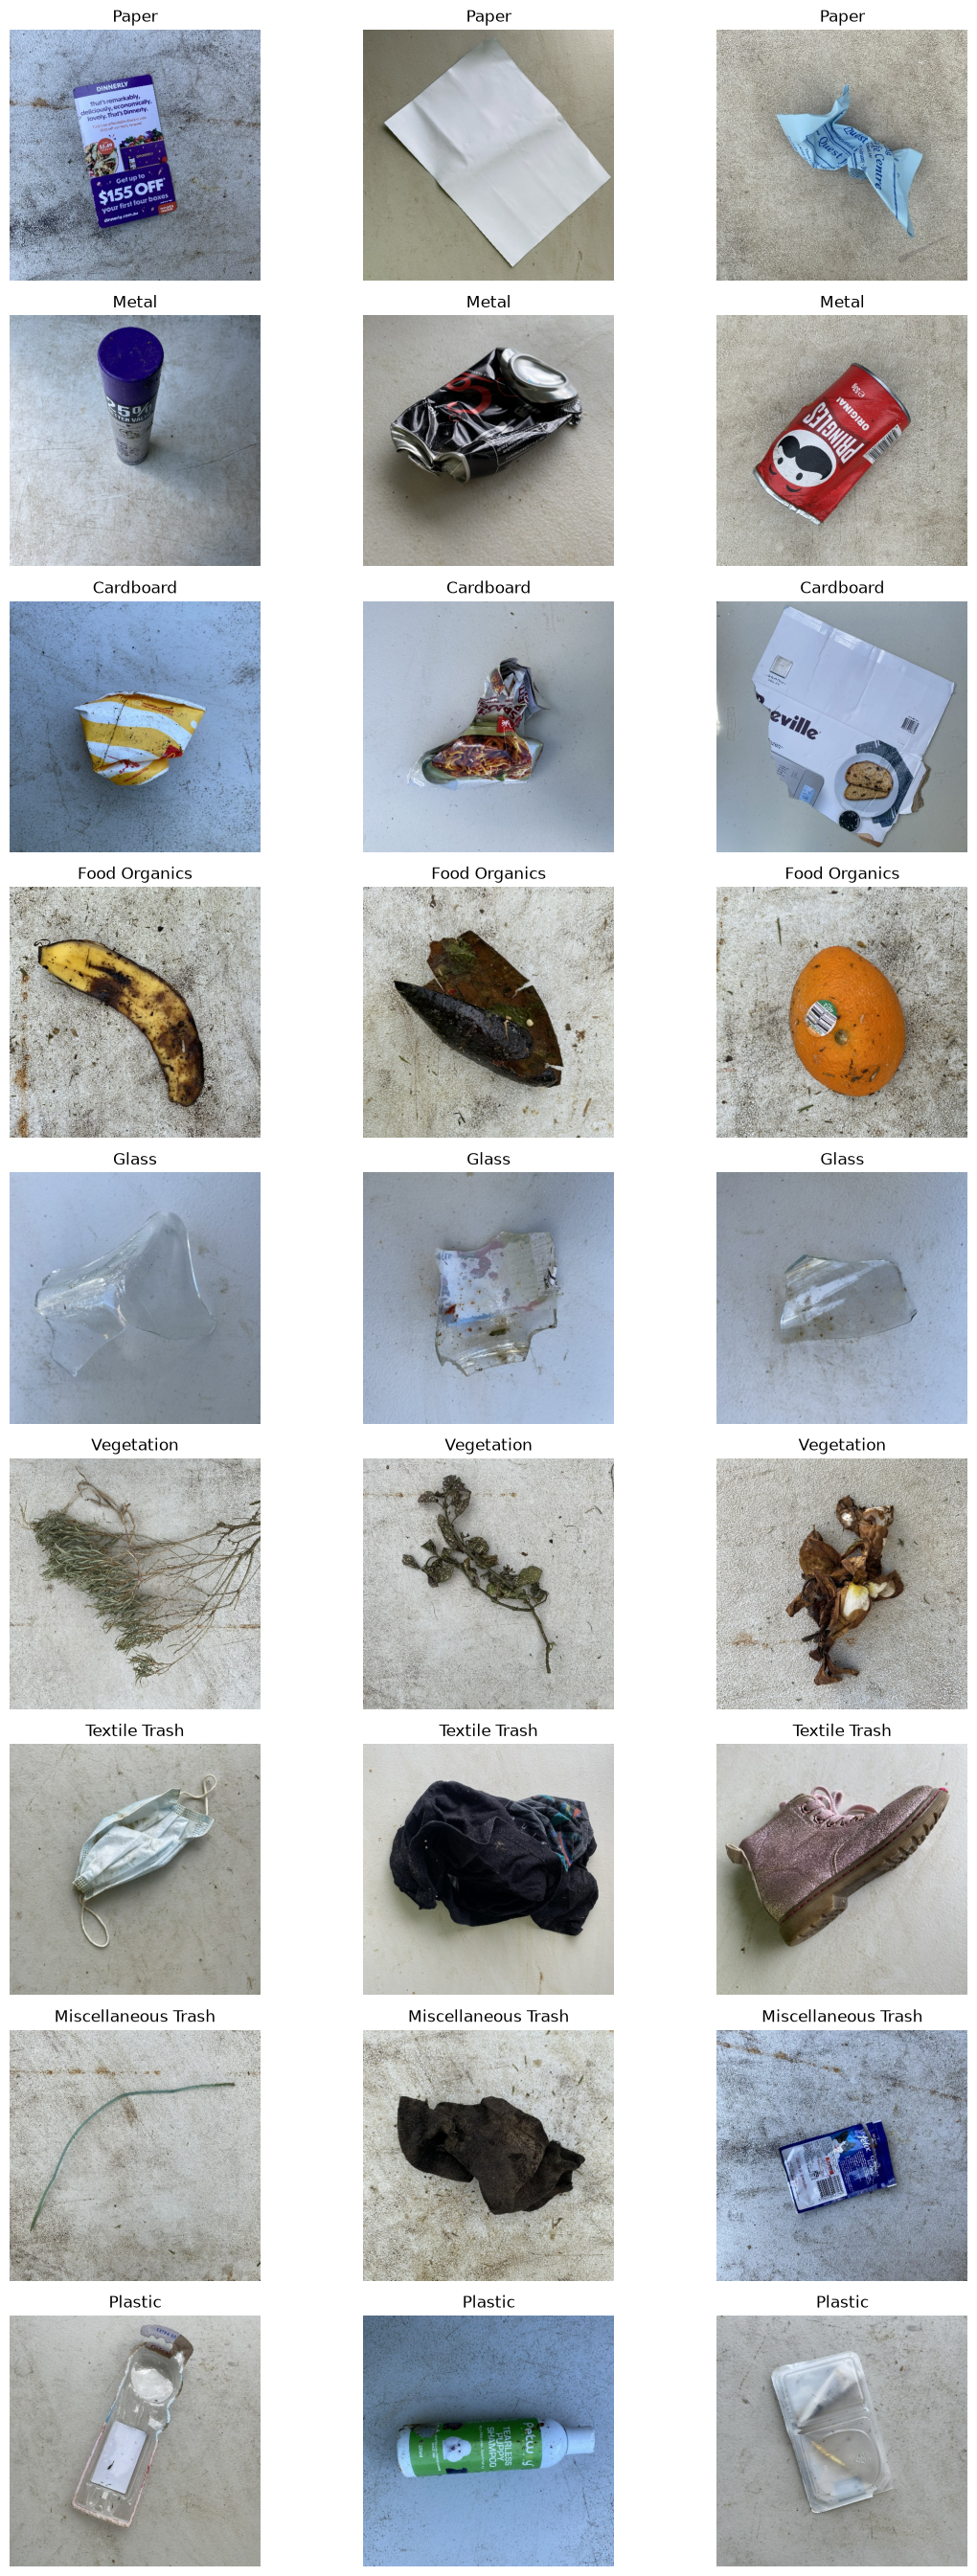

In [6]:
# sample images

# Display 3 sample images from each category
plt.figure(figsize=(12, 3 * len(category_df)))

for i, category in enumerate(category_df["Category"]):
    category_path = os.path.join(DATASET_PATH, category)

    images = [
        img for img in os.listdir(category_path)
        if img.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_images = random.sample(images, min(3, len(images)))

    for j, filename in enumerate(sample_images):
        image_path = os.path.join(category_path, filename)

        img = Image.open(image_path)

        plt.subplot(len(category_df), 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(category)
        plt.axis("off")

plt.tight_layout()
plt.show()

### 1.2 Explore Text Datasets

In [7]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
text_df = pd.read_csv("waste_descriptions.csv")

text_df.head(10)

,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...
5,wrinkled pink takeout container with product r...,Plastic,Remove labels if possible.,Plastic bags often can not go in general recyc...,Polymer materials derived from petrochemicals ...
6,broken glass container,Glass,"Remove caps, lids, and corks before recycling.","Window glass, drinking glasses, and ceramics s...","Silica-based material, may contain additives f..."
7,clean red grass clippings,Vegetation,Large branches may need to be cut to appropria...,NaN,Plant matter composed primarily of cellulose a...
8,Designer egg carton,Cardboard,"If contaminated with food, tear off contaminat...",Pizza boxes with food stains should go in orga...,Thick paper pulp formed into corrugated or sol...
9,wrinkled metal cutlery with food residue,Metal,"For aerosol cans, ensure they are completely e...",NaN,"Aluminum, steel, tin or mixed metal alloys."


Description Length Statistics:


count    5000.000000
mean        4.854000
std         1.549956
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        10.000000
Name: word_count, dtype: float64

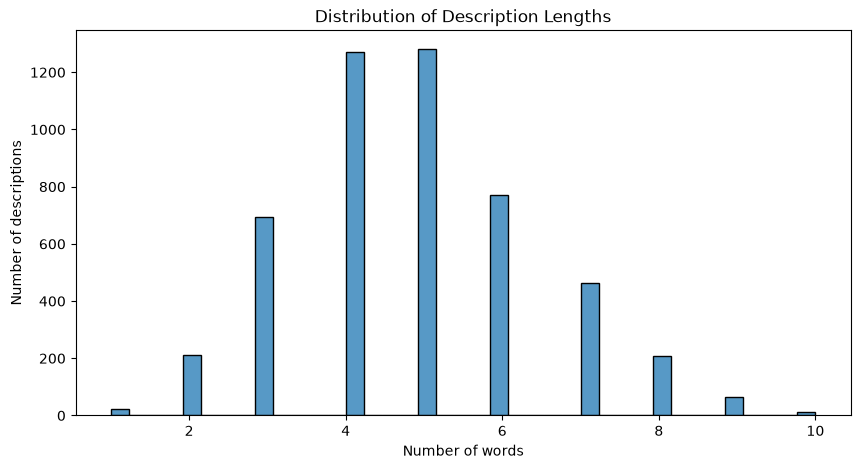

In [8]:
# - Analyze vocabulary and structure

# word count for each description
text_df["word_count"] = text_df["description"].fillna("").str.split().str.len()

print("Description Length Statistics:")
display(text_df["word_count"].describe())

# visualize description lengths
plt.figure(figsize=(10, 5))
sns.histplot(text_df["word_count"])

plt.title("Distribution of Description Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of descriptions")
plt.show()


In [9]:
# combine descriptions into one string
all_text = " ".join(text_df["description"].dropna()).lower()

# split text into individual words
words = all_text.split()

# count unique words
vocabulary = set(words)

print("Total Words:", len(words))
print("Unique Words:", len(vocabulary))

# find 20 most common words
word_counts = Counter(words)

print("\n20 most common words:")
display(pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Count"]
))

Total Words: 24270
Unique Words: 305

20 most common words:


,Word,Count
0,with,727
1,glass,424
2,empty,348
3,bottle,342
4,food,316
5,paper,316
6,box,313
7,residue,309
8,plastic,251
9,brand,247


Waste Category Distribution:


category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64

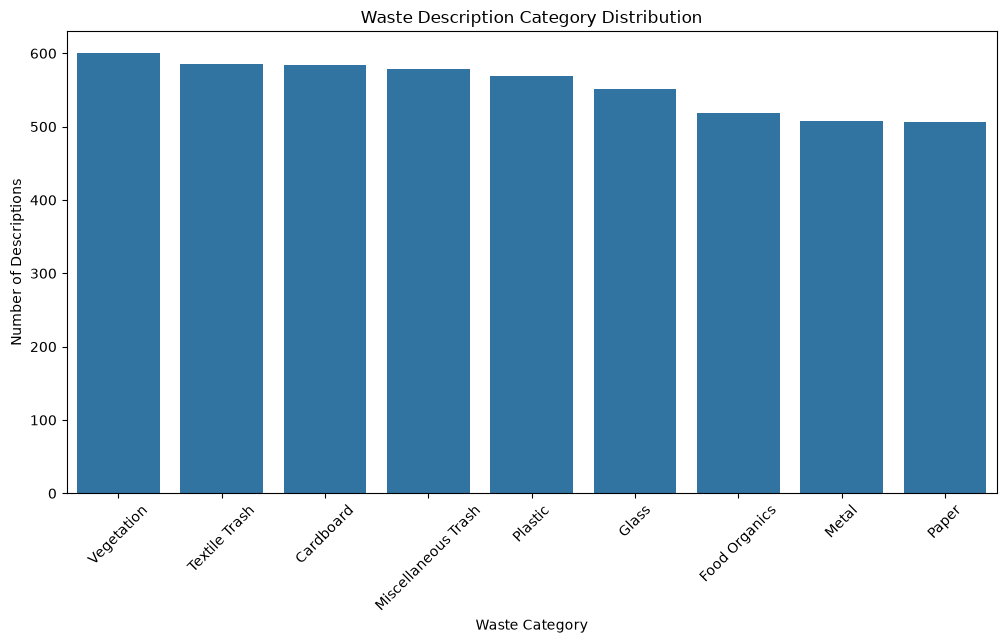

In [10]:
# - Understand the distribution of categories
# Count descriptions in each category
category_counts = text_df["category"].value_counts()

# Display category counts
print("Waste Category Distribution:")
display(category_counts)

# Plot category distribution
plt.figure(figsize=(12, 6))
sns.barplot(x=category_counts.index, y=category_counts.values)

plt.title("Waste Description Category Distribution")
plt.xlabel("Waste Category")
plt.ylabel("Number of Descriptions")
plt.xticks(rotation=45)
plt.show()

In [11]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
with open("waste_policy_documents.json", "r") as file:
    policies = json.load(file)

# convert to DF
policy_df = pd.DataFrame(policies)

# Display first 5 policies
policy_df.head()

,policy_id,policy_type,categories_covered,effective_date,document_text,jurisdiction
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,GLASS RECYCLING GUIDELINES\n\nAcceptable Items...,Metro City
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...,Metro City
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...,Metro City


In [12]:
# - Understand document organization and language

# Document organization

print("\nColumn Names:")
print(policy_df.columns.tolist())

print("\nDataset Information:")
policy_df.info()

# Count policies by type
print("\nPolicy Types:")
display(policy_df["policy_type"].value_counts())

# Display categories covered
print("\nCategories Covered:")
display(policy_df["categories_covered"].explode().value_counts())

# Display jurisdictions
print("\nJurisdications:")
display(policy_df["jurisdiction"].explode().value_counts())


Column Names:
['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   policy_id           14 non-null     int64 
 1   policy_type         14 non-null     str   
 2   categories_covered  14 non-null     object
 3   effective_date      14 non-null     str   
 4   document_text       14 non-null     str   
 5   jurisdiction        14 non-null     str   
dtypes: int64(1), object(1), str(4)
memory usage: 10.8+ KB

Policy Types:


policy_type
Textile Trash Recycling Guidelines          1
Glass Recycling Guidelines                  1
Food Organics Recycling Guidelines          1
Plastic Recycling Guidelines                1
Vegetation Recycling Guidelines             1
Cardboard Recycling Guidelines              1
Metal Recycling Guidelines                  1
Paper Recycling Guidelines                  1
Miscellaneous Trash Recycling Guidelines    1
Municipal Waste Guidelines                  1
Residential Recycling Rules                 1
Commercial Recycling Standards              1
Multi-Unit Building Guidelines              1
Community Recycling Program                 1
Name: count, dtype: int64


Categories Covered:


categories_covered
Vegetation             4
Metal                  4
Miscellaneous Trash    4
Textile Trash          3
Glass                  3
Plastic                3
Cardboard              3
Food Organics          2
Paper                  1
Name: count, dtype: int64


Jurisdications:


jurisdiction
Metro City    14
Name: count, dtype: int64

Policy Document Length Statistics:


count     14.000000
mean     101.785714
std       15.115853
min       86.000000
25%       94.250000
50%       99.000000
75%      102.000000
max      146.000000
Name: word_count, dtype: float64

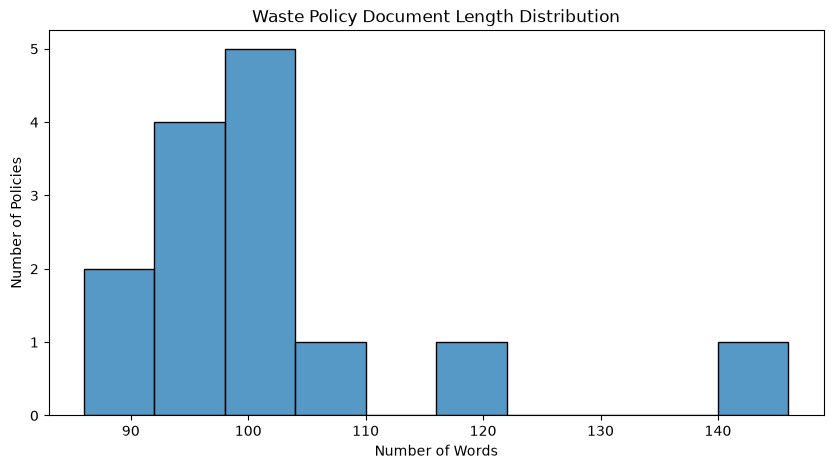

In [13]:
# Document language

# Calculate word count for each policy
policy_df["word_count"] = policy_df["document_text"].str.split().str.len()

# Display word count statistics
print("Policy Document Length Statistics:")
display(policy_df["word_count"].describe())

# Plot document lengths
plt.figure(figsize=(10, 5))
sns.histplot(policy_df["word_count"])

plt.title("Waste Policy Document Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Policies")
plt.show()

### 1.3 Create Data Pipelines

In [41]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('./realwaste-main/RealWaste/')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [42]:
# TODO: Create a text preprocessing pipeline
# - Text cleaning

# Load text dataset if not already loaded
text_df = pd.read_csv("waste_descriptions.csv")

# Remove rows with missing descriptions or categories
text_df = text_df.dropna(subset=["description", "category"]).copy()

# Function to clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", "", text)
    return text.strip()

# Apply cleaning
text_df["clean_description"] = text_df["description"].apply(clean_text)

# Display cleaned descriptions
display(text_df[["description", "clean_description"]].head())

,description,clean_description
0,soiled silver tablecloth,soiled silver tablecloth
1,folded glass bottle leaking,folded glass bottle leaking
2,large Supermarket vegetable waste with food re...,large supermarket vegetable waste with food re...
3,intact floral carpet piece,intact floral carpet piece
4,empty fun-sized purple apple core,empty funsized purple apple core


In [43]:
# Encode waste cetegories

# Convert category names to numerical labels
label_encoder = LabelEncoder()

text_df["label"] = label_encoder.fit_transform(text_df["category"])

# Display category mappings
for i, category in enumerate(label_encoder.classes_):
    print(f"{i}: {category}")

# Number of classes
num_text_classes = len(label_encoder.classes_)

0: Cardboard
1: Food Organics
2: Glass
3: Metal
4: Miscellaneous Trash
5: Paper
6: Plastic
7: Textile Trash
8: Vegetation


In [44]:
# - Split data into train and test
X = text_df["clean_description"]
y = text_df["label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [45]:
# - Tokenization

# Set vocabulary size and sequence length
MAX_TOKENS = 5000
MAX_LENGTH = 30

# Create text vectorization layer
vectorizer = TextVectorization(max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

# Learn vocabulary from training data only
vectorizer.adapt(X_train.to_numpy())

# Convert text into numerical sequences
X_train_seq = vectorizer(X_train.to_numpy())
X_test_seq = vectorizer(X_test.to_numpy())

print("Training Sequence Shape:", X_train_seq.shape)
print("Testing Sequence Shape:", X_test_seq.shape)

# Display an example
print("\nOriginal Description:")
print(X_train.iloc[0])

print("\nTokenized Sequence:")
print(X_train_seq[0].numpy())


Training Sequence Shape: (4000, 30)
Testing Sequence Shape: (1000, 30)

Original Description:
enormous pink flyer

Tokenized Sequence:
[ 24  59 266   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0]


In [46]:
# - Create embeddings/features
# Define embedding dimensions
EMBEDDING_DIM = 64

# Create embedding layer
embedding_layer = Embedding(
    input_dim=MAX_TOKENS,
    output_dim=EMBEDDING_DIM,
    mask_zero=True
)

# Generate embeddings for a sample
sample_embedding = embedding_layer(X_train_seq[:1])

print("Embedding Shape:", sample_embedding.shape)

Embedding Shape: (1, 30, 64)


In [47]:
# TODO: Prepare documents for RAG
# - Document preprocessing

# Handle missing values
policy_df["document_text"] = policy_df["document_text"].fillna("")
policy_df["policy_type"] = policy_df["policy_type"].fillna("")

# Combine relevant information into one text field
policy_df["processed_text"] = (
    policy_df["policy_type"] + ". " +
    policy_df["categories_covered"].apply(lambda x: ", ".join(x)) + ". " +
    policy_df["document_text"]
)

# Remove extra whitespace
policy_df["processed_text"] = (
    policy_df["processed_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Display example
print(policy_df["processed_text"].iloc[0])

Textile Trash Recycling Guidelines. Textile Trash. TEXTILE RECYCLING GUIDELINES Acceptable Items: - Clean clothing (all conditions) - Towels, sheets, and linens - Fabric scraps - Curtains and cloth napkins - Handbags and backpacks made of fabric - Soft toys and stuffed animals Non-Acceptable Items: - Wet or moldy textiles - Heavily soiled items - Carpets and rugs - Footwear - Items with significant non-textile parts Collection Method: Place items in dedicated textile recycling bins or donate to local thrift stores. Preparation Instructions: - Ensure all items are clean and dry - Remove non-textile components when possible - Bag similar items together Benefits: Textile recycling conserves resources and reduces landfill waste.


In [48]:
# - Create embeddings for retrieval

# Load pretrained embedding model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Generate embeddings for policy documents
document_embeddings = embedding_model.encode(
    policy_df["processed_text"].tolist(),
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Document Embeddings Shape:", document_embeddings.shape)

/Users/mikeb/miniconda3/envs/bert_nlp/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Document Embeddings Shape: (14, 384)


## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [49]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Normalize pixel values from 0-255 to 0-1
def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

# Apply normalization to all datasets
train_ds = train_ds.map(normalize_images)
validation_ds = validation_ds.map(normalize_images)
test_dataset = test_dataset.map(normalize_images)

# Check image shapes and pixel values
for images, labels in train_ds.take(1):
    print("Image Shape:", images.shape)
    print("Label Shape:", labels.shape)
    print("Minimum Pixel Value:", tf.reduce_min(images).numpy())
    print("Maximum Pixel Value:", tf.reduce_max(images).numpy())

Image Shape: (32, 224, 224, 3)
Label Shape: (32, 9)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


2026-10-23 10:08:16.894286: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


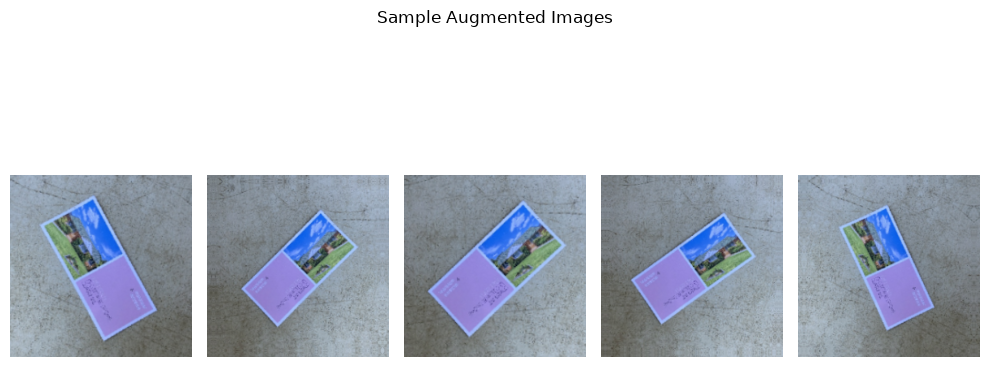

2026-10-23 10:08:17.232637: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
# Create image augmentation pipeline
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# Display original and augmented images
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 5))

    for i in range(5):
        augmented_image = data_augmentation(
            images[0:1], training=True
        )
        plt.subplot(1, 5, i + 1)
        plt.imshow(augmented_image[0].numpy())
        plt.axis("off")

    plt.suptitle("Sample Augmented Images")
    plt.show()

### 2.2 Implement CNN Model with Transfer Learning

In [69]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Load pretrained MobileNetV2 without its classification layer
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully


In [70]:
# Build CNN model using transfer learning
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Image augmentation
    data_augmentation,

    # Convert normalized pixels from [0, 1] to [-1, 1]
    layers.Rescaling(2.0, offset=-1.0),

    # Pretrained MobileNetV2
    base_model,

    # Custom classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

# Display model architecture
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [71]:
# Compile CNN model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully")

CNN model compiled successfully


In [72]:
# Display model summary
model.summary()

# Check number of trainable parameters
print("Trainable Parameters:",
      sum(tf.size(w).numpy() for w in model.trainable_weights))

print("Number of Waste Categories:", num_classes)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable Parameters: 165129
Number of Waste Categories: 9


### 2.3 Train and Evaluate the Model

In [74]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Configure training callbacks
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "best_waste_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

In [75]:
# Train CNN model
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


/Users/mikeb/miniconda3/envs/bert_nlp/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 68s 536ms/step - accuracy: 0.5708 - loss: 1.2253 - val_accuracy: 0.7213 - val_loss: 0.7690 - learning_rate: 0.0010
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 67s 564ms/step - accuracy: 0.7330 - loss: 0.7725 - val_accuracy: 0.7617 - val_loss: 0.6997 - learning_rate: 0.0010
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 71s 597ms/step - accuracy: 0.7788 - loss: 0.6181 - val_accuracy: 0.7638 - val_loss: 0.6324 - learning_rate: 0.0010
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 76s 634ms/step - accuracy: 0.8122 - loss: 0.5394 - val_accuracy: 0.8043 - val_loss: 0.5484 - learning_rate: 0.0010
Epoch 5/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 74s 618ms/step - accuracy: 0.8267 - loss: 0.4838 - val_accuracy: 0.8064 - val_loss: 0.5698 - learning_rate: 0.0010
Epoch 6/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 69s 575ms/step - accuracy: 0.8440 - loss: 0.4601 - val_accuracy: 0.7957 - val_loss: 0.6610 - learning_rate: 0.0010
Epoch 7/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 70s 585ms/step - accuracy: 0.8622 - loss:

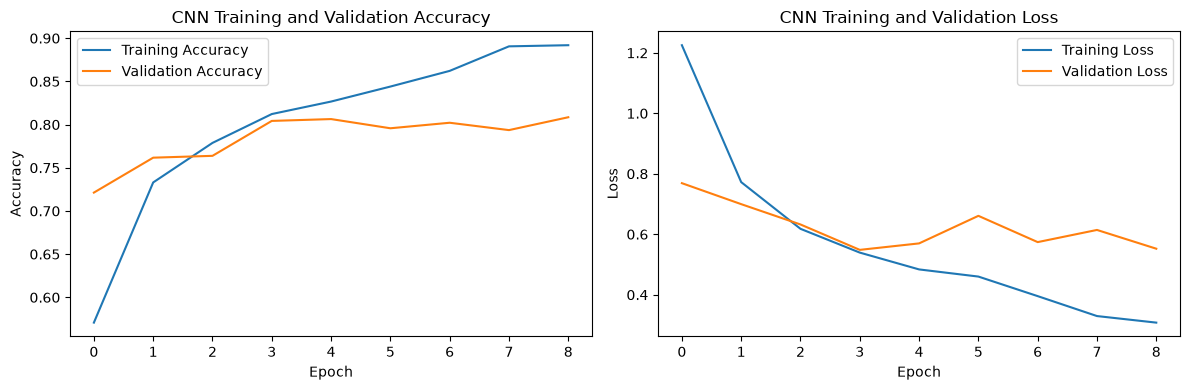

In [76]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [77]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Evaluate model on test data
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 459ms/step - accuracy: 0.7979 - loss: 0.5796
Test Loss: 0.5796
Test Accuracy: 79.79%


In [78]:
# Get actual labels and model predictions
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total Test Images:", len(y_true))
print("Correct Predictions:", np.sum(y_true == y_pred))
print("Incorrect Predictions:", np.sum(y_true != y_pred))

Total Test Images: 480
Correct Predictions: 372
Incorrect Predictions: 108


2026-10-23 10:24:27.801950: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


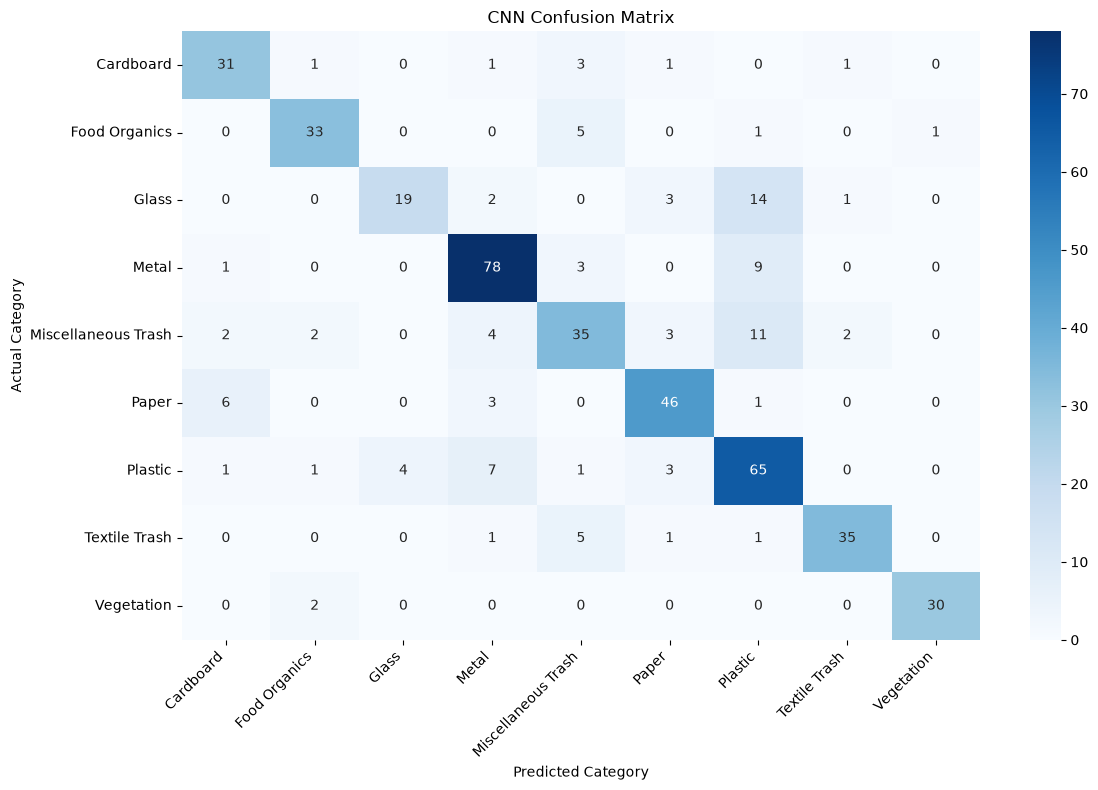

In [79]:
# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

# Plot confusion matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [80]:
# Generate classification report
print("CNN Classification Report:")

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Calculate errors by category
errors = cm.sum(axis=1) - np.diag(cm)

error_df = pd.DataFrame({
    "Category": class_names,
    "Total Images": cm.sum(axis=1),
    "Incorrect Predictions": errors,
    "Error Rate (%)": np.divide(
        errors,
        cm.sum(axis=1),
        out=np.zeros(len(errors), dtype=float),
        where=cm.sum(axis=1) != 0
    ) * 100
})

# Sort by error rate
error_df = error_df.sort_values(
    "Error Rate (%)",
    ascending=False
)

print("\nClassification Errors by Category:")
display(error_df)

CNN Classification Report:
                     precision    recall  f1-score   support

          Cardboard       0.76      0.82      0.78        38
      Food Organics       0.85      0.82      0.84        40
              Glass       0.83      0.49      0.61        39
              Metal       0.81      0.86      0.83        91
Miscellaneous Trash       0.67      0.59      0.63        59
              Paper       0.81      0.82      0.81        56
            Plastic       0.64      0.79      0.71        82
      Textile Trash       0.90      0.81      0.85        43
         Vegetation       0.97      0.94      0.95        32

           accuracy                           0.78       480
          macro avg       0.80      0.77      0.78       480
       weighted avg       0.78      0.78      0.77       480


Classification Errors by Category:


,Category,Total Images,Incorrect Predictions,Error Rate (%)
2,Glass,39,20,51.282051
4,Miscellaneous Trash,59,24,40.677966
6,Plastic,82,17,20.731707
7,Textile Trash,43,8,18.604651
0,Cardboard,38,7,18.421053
5,Paper,56,10,17.857143
1,Food Organics,40,7,17.500000
3,Metal,91,13,14.285714
8,Vegetation,32,2,6.250000


### 2.4 Fine-tune the Model

In [82]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Allow fine-tuning of MobileNetV2
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable layers: 19


In [83]:
# Add L2 regularization to the Dense layer
dense_layer = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dense)
    and layer.units == 128
)

dense_layer.kernel_regularizer = regularizers.l2(0.001)

# Recompile with a smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [84]:
# Fine-tune the model
fine_tune_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10


/Users/mikeb/miniconda3/envs/bert_nlp/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 86s 671ms/step - accuracy: 0.8414 - loss: 0.4455 - val_accuracy: 0.8340 - val_loss: 0.5072 - learning_rate: 1.0000e-05
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 90s 757ms/step - accuracy: 0.8601 - loss: 0.3942 - val_accuracy: 0.8149 - val_loss: 0.5456 - learning_rate: 1.0000e-05
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 673ms/step - accuracy: 0.8745 - loss: 0.3688 - val_accuracy: 0.8085 - val_loss: 0.5548 - learning_rate: 1.0000e-05
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 670ms/step - accuracy: 0.8743 - loss: 0.3588 - val_accuracy: 0.8191 - val_loss: 0.5027 - learning_rate: 1.0000e-05
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 82s 689ms/step - accuracy: 0.8937 - loss: 0.3071 - val_accuracy: 0.8170 - val_loss: 0.5085 - learning_rate: 1.0000e-05
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 81s 680ms/step - accuracy: 0.8956 - loss: 0.3025 - val_accuracy: 0.8234 - val_loss: 0.4863 - learning_rate: 1.0000e-05
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 671ms/step - 

15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 557ms/step - accuracy: 0.8396 - loss: 0.4803
Original Test Accuracy: 79.79%
Tuned Test Accuracy: 83.96%
Accuracy Improvement: 4.17 percentage points


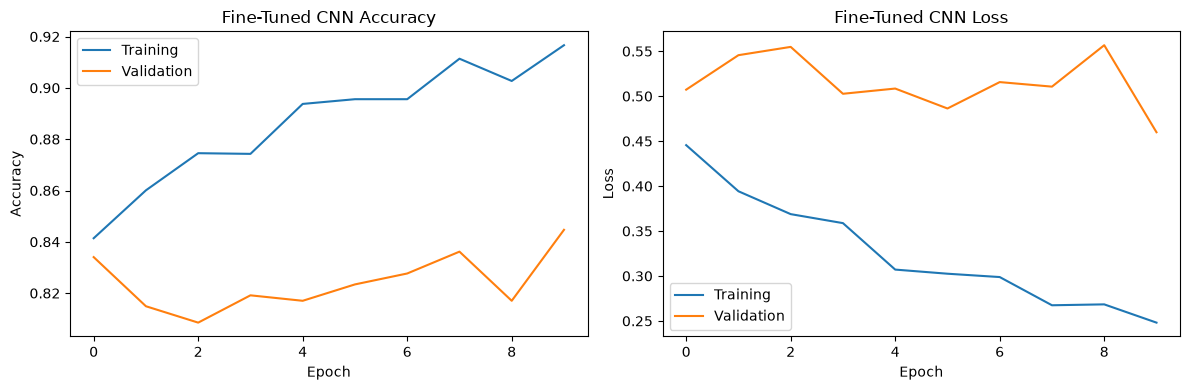

In [85]:
# Evaluate fine-tuned model
tuned_loss, tuned_accuracy = model.evaluate(test_dataset)

print(f"Original Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Tuned Test Accuracy: {tuned_accuracy * 100:.2f}%")
print(f"Accuracy Improvement: {(tuned_accuracy - test_accuracy) * 100:.2f} percentage points")

# Plot fine-tuning accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(fine_tune_history.history["accuracy"], label="Training")
plt.plot(fine_tune_history.history["val_accuracy"], label="Validation")
plt.title("Fine-Tuned CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fine_tune_history.history["loss"], label="Training")
plt.plot(fine_tune_history.history["val_loss"], label="Validation")
plt.title("Fine-Tuned CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [ ]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Your code here 

### 3.2 Implement Text Classification Model

In [56]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Your code here

### 3.3 Train and Evaluate the Model

In [57]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Your code here

In [58]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here

### 3.4 Create Classification Function

In [59]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Your code here
    pass

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [60]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Your code here

### 4.2 Implement RAG-based System

In [61]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Your code here

### 4.3 Adjust and Evaluate the System

In [62]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Your code here

In [63]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Your code here

### 4.4 Create Instruction Generation Function

In [64]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    # Your code here
    pass

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [65]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

# Your code here

### 5.2 Implement Integrated Assistant

In [66]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Your code here
    pass

### 5.3 Evaluate the Integrated System

In [67]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Your code here

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.